# 1. Antennas

The transmitter is a **monopole** and the receiver is a **ring of dipoles or folded dipoles**, with an optional central vertical column for elevation. Antennas come first because their patterns enter every later stage.

## Element patterns

A half-wave dipole has the far-field pattern (Balanis, *Antenna Theory*, ch. 4)

$$F(\theta) = \frac{\cos\left(\frac{\pi}{2}\cos\theta\right)}{\sin\theta}$$

with $\theta$ measured from the dipole axis. Numerical integration of $F^2$ gives a directivity of 1.64, or 2.15 dBi. A folded dipole has the same pattern, with about four times the feed impedance and a wider bandwidth. A quarter-wave monopole on an ideal ground plane is the upper half of this pattern at twice the gain, so 5.15 dBi.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
# Run from the notebooks folder, or from the project root.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from bistatic_lb import Scenario, run_link_budget, plots

from bistatic_lb.antenna.elements import DIPOLE_DIRECTIVITY, MonopoleTx, mismatch_loss_db, usable_band_hz
from bistatic_lb.antenna import array_from_scenario

print(f"Dipole directivity: {10*np.log10(DIPOLE_DIRECTIVITY):.2f} dBi")
print(f"Ideal monopole at the horizon: {MonopoleTx().gain_dbi(0.0):.2f} dBi")
print(f"Monopole with a finite ground plane: {MonopoleTx(finite_ground=True).gain_dbi(0.0):.2f} dBi at the horizon")


Dipole directivity: 2.15 dBi
Ideal monopole at the horizon: 5.16 dBi
Monopole with a finite ground plane: -0.84 dBi at the horizon


## A dipole does not cover the whole band

The tool accepts 50 MHz to 18 GHz, but a resonant element works over a limited band around its design frequency. A single-resonance model gives the reflection loss. It is a planning approximation, not an EM result.

dipole: VSWR below 2 from 574 to 627 MHz
folded_dipole: VSWR below 2 from 549 to 655 MHz


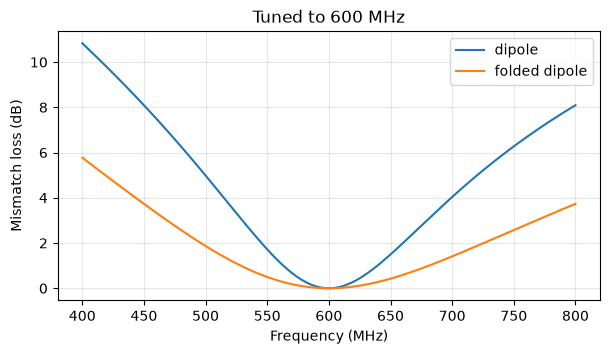

In [2]:
f = np.linspace(400e6, 800e6, 201)
fig, ax = plt.subplots(figsize=(7, 3.5))
for name in ("dipole", "folded_dipole"):
    ax.plot(f/1e6, [mismatch_loss_db(x, 600e6, name) for x in f], label=name.replace("_", " "))
    low, high = usable_band_hz(600e6, name)
    print(f"{name}: VSWR below 2 from {low/1e6:.0f} to {high/1e6:.0f} MHz")
ax.set(xlabel="Frequency (MHz)", ylabel="Mismatch loss (dB)", title="Tuned to 600 MHz")
ax.legend(); ax.grid(alpha=0.3); plt.show()


## The array

For unit-norm weights $w$ and a plane wave from direction $u$, the output power gain is

$$G(u) = |w^H a(u)|^2,\qquad a_n(u) = \sqrt{g_n(u)}\; e^{\,j k\, p_n \cdot u}$$

With $\|w\|=1$, uncorrelated receiver noise keeps unit gain whatever the weights are, so $G$ compares directly with an isotropic antenna. A large uniform ring has an azimuth pattern close to $J_0^2$, whose first sidelobe is only about 8 dB down. That is a high sidelobe level for direct-path and clutter rejection, and the ring's main weakness.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


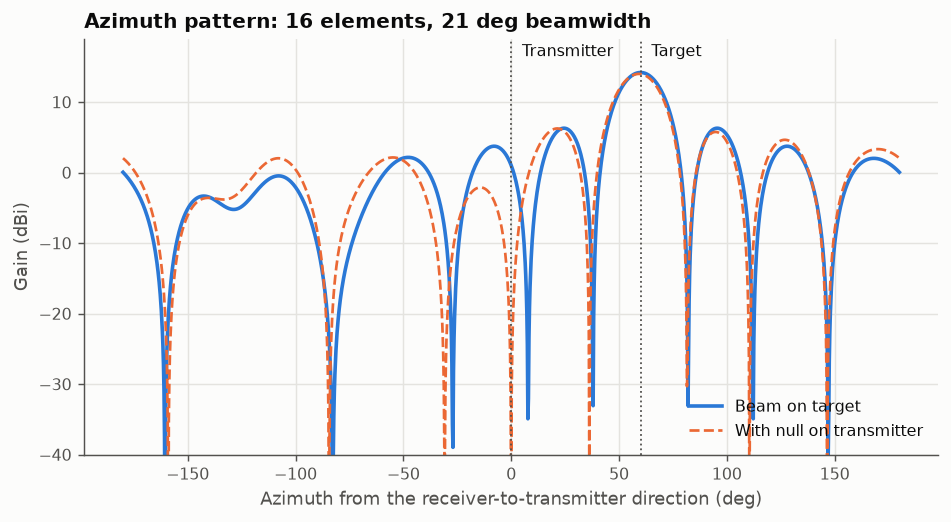

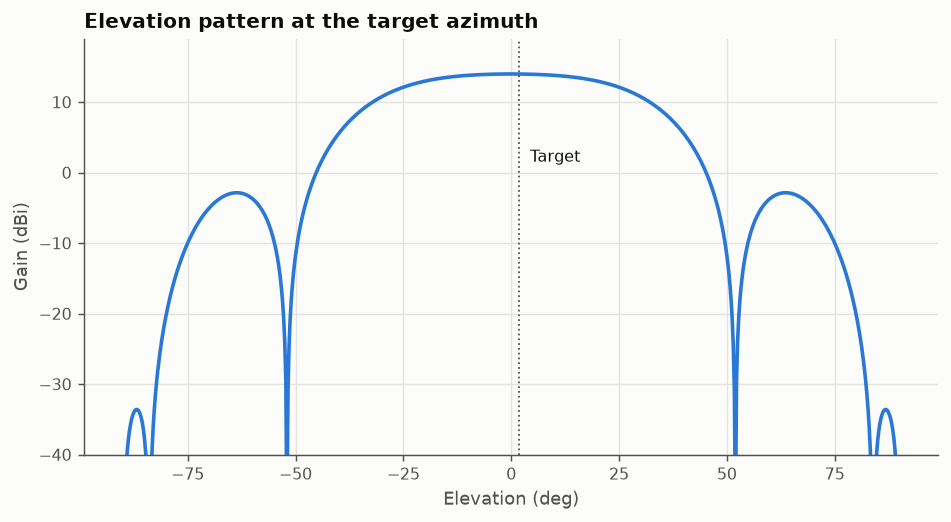

Beamwidth 21.0 deg, peak sidelobe -7.9 dB, spacing 0.39 wavelengths


In [3]:
s = Scenario()
r = run_link_budget(s)
plots.azimuth_pattern(r); plots.elevation_pattern(r); plt.show()
print(f"Beamwidth {r.antenna.beamwidth_az_deg:.1f} deg, peak sidelobe {r.antenna.peak_sidelobe_db:.1f} dB, spacing {r.antenna.max_spacing_wavelengths:.2f} wavelengths")


### Check: ring pattern against the $J_0$ form

In [4]:
from scipy.special import j0
big = Scenario(); big.array.n_circular, big.array.radius_wavelengths = 64, 3.0
arr = array_from_scenario(big); w = arr.beamformer(0.0, 0.0)
psi = np.deg2rad(np.linspace(0, 180, 361))
model = arr.gain_linear(w, psi, np.zeros_like(psi)) / arr.gain_linear(w, 0.0, 0.0)
theory = j0(2*np.pi*3.0*2*np.sin(psi/2))**2
print(f"Largest difference from J0^2: {np.max(np.abs(model-theory)):.1e}")


Largest difference from J0^2: 3.9e-11


## Trade-off: radius, element count and aliasing

Too few elements for the radius brings aliased sidelobes. Those can be nearly as strong as the main lobe, which causes angle ambiguity. A useful rule is that adjacent spacing should stay under about half a wavelength.

In [5]:
rows = []
for n in (8, 12, 16, 24, 32):
    for radius in (0.5, 1.0, 2.0):
        t = Scenario(); t.array.n_circular, t.array.radius_wavelengths = n, radius
        a = array_from_scenario(t); w = a.beamformer(1.0, 0.03)
        rows.append((n, radius, a.max_spacing_wavelengths(), float(a.gain_dbi(w, 1.0, 0.03)), a.beamwidth_az_deg(w, 1.0, 0.03), a.peak_sidelobe_db(w, 1.0, 0.03)))
print("Elements  Radius  Spacing  Gain dBi  Beamwidth deg  Sidelobe dB")
for row in rows:
    print("{:8d}  {:6.1f}  {:7.2f}  {:8.1f}  {:13.1f}  {:11.1f}".format(*row))


Elements  Radius  Spacing  Gain dBi  Beamwidth deg  Sidelobe dB
       8     0.5     0.38      11.2           41.5         -7.8
       8     1.0     0.77      11.2           21.0         -1.3
       8     2.0     1.53      11.2           10.5         -1.6
      12     0.5     0.26      12.9           41.5         -7.9
      12     1.0     0.52      12.9           21.0         -4.1
      12     2.0     1.04      12.9           10.5         -2.2
      16     0.5     0.20      14.2           41.5         -7.9
      16     1.0     0.39      14.2           21.0         -7.9
      16     2.0     0.78      14.2           10.5         -4.1
      24     0.5     0.13      15.9           41.5         -7.9
      24     1.0     0.26      15.9           21.0         -7.9
      24     2.0     0.52      15.9           10.5         -5.8
      32     0.5     0.10      17.2           41.5         -7.9
      32     1.0     0.20      17.2           21.0         -7.9
      32     2.0     0.39      17.2     

## Angle accuracy from the geometry

The Cramer-Rao bound comes directly from the array's Fisher information, using the actual element positions. The simulated maximum-likelihood estimator should meet the bound once SNR clears the threshold.

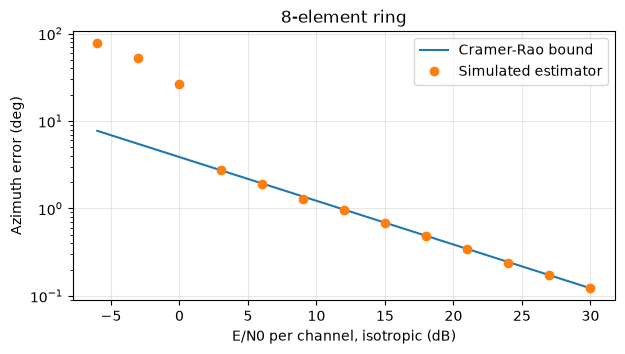

In [6]:
from bistatic_lb.target.montecarlo import angle_estimator_rmse
t = Scenario(); t.array.n_circular, t.array.radius_wavelengths = 8, 0.65
arr = array_from_scenario(t)
snr = np.arange(-6, 31, 3.0)
bound = np.array([arr.angle_crlb_rad(10**(v/10), 0.5, 0.0)[0] for v in snr])
measured = angle_estimator_rmse(arr, 0.5, 0.0, snr, trials=500)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(snr, np.rad2deg(bound), label="Cramer-Rao bound")
ax.semilogy(snr, np.rad2deg(measured), "o", label="Simulated estimator")
ax.set(xlabel="E/N0 per channel, isotropic (dB)", ylabel="Azimuth error (deg)", title="8-element ring"); ax.legend(); ax.grid(alpha=0.3); plt.show()


## Limitations

- **Mutual coupling is neglected.** It matters most for close spacing and deep nulls. If the no-coupling gain integrates to well above 0 dB over the sphere, the tool warns that gains may be high. Override `ReceiveArray.element_gain` to use measured or EM patterns.
- The monopole's finite-ground correction is empirical, and the tool marks it as approximate.